# AI를위한수학의기초 - 8. 회귀분석(2)

## 1) 학습시간(X)에 따른 시험점수(Y) 데이터

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 생성
data = {
    'Study_time' : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Score' : [52, 58, 61, 67, 72, 75, 82, 88, 92, 95]
}
df = pd.DataFrame(data)

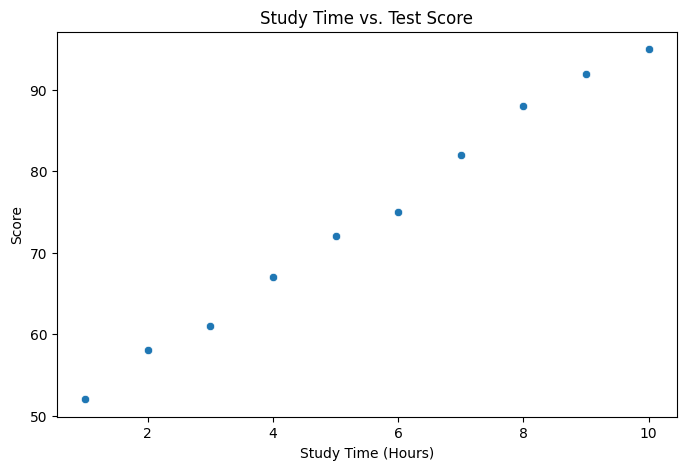

In [6]:
# 2. 산점도 시각화
plt.figure(figsize=(8,5))
sns.scatterplot(x='Study_time', y="Score", data = df)
plt.title("Study Time vs. Test Score")
plt.xlabel("Study Time (Hours)")
plt.ylabel("Score")
plt.show()

## 2) 회귀모형 적합을 통한 통계적 추론

- Statemodels 이용하여 선형회귀모형 구현
- 설명 변수에 절편항(intercept) 추가
- Statemodels의 OLS(최소제곱법) 패키지 이용하여 모형 적합

In [7]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# [1] Statsmodels를 이용한 단순선형회귀 (학습시간 -> 시험점수)
# ------------------------------------------------------------
# scikit-learn과 달리 statsmodels는 y절편(상수항)을 자동으로 추가하지 않으므로 직접 추가해야 합니다.
X = sm.add_constant(df['Study_time'])
y = df['Score']

# OLS(Ordinary Least Squares, 최소제곱법) 방식으로 모형을 학습(fit)시킵니다.
model = sm.OLS(y, X).fit()

# 회귀계수(coef), p-value(P>|t|), 결정계수(R-squared) 등 통계 분석 요약표를 출력합니다.
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     1716.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.27e-10
Time:                        08:16:40   Log-Likelihood:                -13.786
No. Observations:                  10   AIC:                             31.57
Df Residuals:                       8   BIC:                             32.18
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         47.2667      0.734     64.436      0.0

coef(회귀계수), P>|t|(p-value), [0.025, 0.972], R-squared(결정계수) 해석하는 것이 중요

In [15]:
# p-vlaue 산출
from scipy import stats

# t_8 qnsvhdptj 4.328 우측의 꼬리 확률 * 2
stats.t(df=8).sf(4.328)*2

np.float64(0.002518759585467296)

In [16]:
# 귀무가설 : \hat{\beta}_1 = 5

# p-value 산출
t_stat = (2.721-5)/0.629
stats.t(df=8).cdf(t_stat)*2

np.float64(0.006751099530467991)

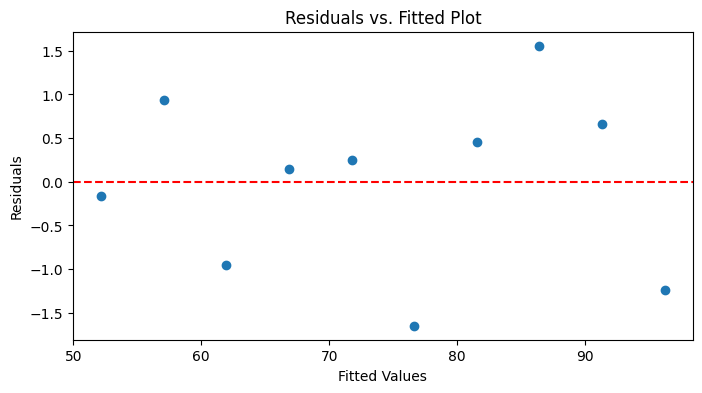

In [10]:
# ------------------------------------------------------------
# [2] 잔차 산점도 (선형성 및 등분산성 점검)
# ------------------------------------------------------------
fitted_values = model.predict(X) # 모델이 예측한 값
residuals = model.resid          # 실제값과 예측값의 차이(잔차)

# 예측값을 x축, 잔차를 y축으로 두고 산점도를 그립니다.
# 데이터 포인트들이 빨간 점선(y=0)을 기준으로 특정한 패턴 없이 무작위로 흩어져 있어야
# 선형성 및 등분산성 가정을 잘 만족하는 좋은 모델입니다.
plt.figure(figsize=(8, 4))
plt.scatter(fitted_values, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Plot')
plt.show()

## 3) 중선형회귀모형의 적합과 과적합

- Seaborn 내장 데이터 세트 tips 사용
- totla_bill(식사 총액)과 size(일행 수)를 통해 tip(팁 금액)을 예측하는 중선형회귀모형 구축


In [14]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Seaborn - load tips
tips = sns.load_dataset('tips')

# 데이터 확인
print(tips[['total_bill', 'size', 'tip']].head())

   total_bill  size   tip
0       16.99     2  1.01
1       10.34     3  1.66
2       21.01     3  3.50
3       23.68     2  3.31
4       24.59     4  3.61


In [17]:
# tips: total_bill, size -> tip 예측

import statsmodels.api as sm

# 설명변수(X), 반응변수(y) 설정
X = tips[['total_bill', 'size']]
X = sm.add_constant(X) # 절편항 추가
y = tips['tip']

# 모델 적합
mlr_model = sm.OLS(y, X).fit()

# 결과 출력
print(mlr_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.463
Method:                 Least Squares   F-statistic:                     105.9
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           9.67e-34
Time:                        08:33:42   Log-Likelihood:                -347.99
No. Observations:                 244   AIC:                             702.0
Df Residuals:                     241   BIC:                             712.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6689      0.194      3.455      0.0

두 설명변수 모두 낮은 p-value를 나타내고 있음  
결정계수 값이 0.468  
=> total_bill과 size가 tips에 유의미한 영향을 미치나 이들 외에도 영향을 주는 요소가 더 있다.   

Scikit-learn : 모델 학습과 예측이라는 머신러닝의 작업흐름에 최적화. 중선형회귀모델 적합 작업 수행

In [19]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# ------------------------------------------------------------
# [1] Scikit-learn을 이용한 다중선형회귀 (식사 총액, 일행 수 -> 팁 예측)
# ------------------------------------------------------------
X = tips[['total_bill', 'size']] # 독립변수 2개 이상 (다중회귀)
y = tips['tip']

# sklearn은 기본적으로 내부에서 절편(intercept)을 계산하므로 상수항을 추가할 필요가 없습니다.
sk_model = LinearRegression()
sk_model.fit(X, y)

# 학습된 회귀계수(기울기)와 절편 확인
print(f"회귀계수(total_bill, size): {sk_model.coef_}")
print(f"절편(beta_0): {sk_model.intercept_:.4f}")

# 모델의 설명력(결정계수 R^2) 산출 (값: 0.4679)
r2 = sk_model.score(X, y)
print(f"결정계수(R2): {r2:.4f}")

회귀계수(total_bill, size): [0.09271334 0.19259779]
절편(beta_0): 0.6689
결정계수(R2): 0.4679


In [20]:
# ------------------------------------------------------------
# [2] 새로운 데이터 예측
# ------------------------------------------------------------
# 훈련된 모델에 새로운 데이터(식사비 30달러, 일행 4명)를 넣어 예상 팁을 도출합니다.
new_data = pd.DataFrame([[30, 4]], columns=['total_bill', 'size'])
prediction = sk_model.predict(new_data)
print(f"예측 결과: {prediction[0]:.2f}달러") # 결과: 4.22달러

예측 결과: 4.22달러


## 4) 과적합(Overfitting) 유도 및 교차검증(CV)
모델이 학습 데이터에만 억지로 끼워 맞춰져 새로운 데이터에서는 성능이 폭락하는 현상과, 이를 방지하기 위한 검증 기법입니다.

In [21]:
# 과적합 모델 유도
# 데이터 부족, 클래스 불균형, 과도한 노이즈, 지나치게 복잡한 모델 등 이유로 발생 가능

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# ------------------------------------------------------------
# [1] 과적합(Overfitting) 시뮬레이션
# ------------------------------------------------------------
# 데이터를 학습용(70%)과 테스트용(30%)으로 무작위 분할합니다.
X_train, X_test, y_train, y_test = train_test_split(
    tips[['total_bill', 'size']], y, test_size=0.3, random_state=42
)

# PolynomialFeatures를 이용해 기존 변수들을 10차항까지 복잡하게 뻥튀기(변환)합니다.
poly = PolynomialFeatures(degree=10, include_bias=False)
X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

# 지나치게 복잡해진 데이터로 회귀모델을 강제 학습시킵니다.
overfit_model = LinearRegression().fit(X_poly_train, y_train)

# 3. 성능비교 (R^2)
train_r2 = r2_score(y_train, overfit_model.predict(X_poly_train))
test_r2 = r2_score(y_test, overfit_model.predict(X_poly_test))

# [과적합 결과]
# 학습 데이터 R2: 0.6558 (자신이 본 데이터는 그럴싸하게 맞춤)
# 테스트 데이터 R2: -364308.2784 (처음 보는 데이터에서는 완전히 엉뚱한 예측을 함)
print(f"학습 데이터 R2: {train_r2:.4f}")
print(f"테스트 데이터 R2: {test_r2:.4f}")

학습 데이터 R2: 0.6558
테스트 데이터 R2: -364308.2784


In [23]:
# ------------------------------------------------------------
# [2] K-Fold 교차검증 (Cross Validation)
# ------------------------------------------------------------

from sklearn.model_selection import cross_val_score

# 중선형회귀 모델 객체 생성
lr = LinearRegression()

# 5-겹 교차검증 (5-Fold CV) 수행
# cross_val_score: 전체 데이터를 5개(cv=5)의 조각(Fold)으로 나눈 뒤,
# 4개 조각으로 학습하고 1개 조각으로 평가하는 과정을 5번 번갈아가며 수행합니다.
cv_scores = cross_val_score(lr, tips[['total_bill', 'size']], y, cv=5)

# 특정 우연에 치우치지 않은 객관적이고 안정적인 모델의 '일반화 성능(평균)'을 얻을 수 있습니다.
print(f"각 폴드별 R2 점수: {cv_scores}")
print(f"평균 R2 점수 (일반화): {np.mean(cv_scores):.4f}")

각 폴드별 R2 점수: [0.53404571 0.61085627 0.51123501 0.25355216 0.41897975]
평균 R2 점수 (일반화): 0.4657
